# EDGAR 01 · How a filing becomes a point-in-time series

`00_tour.ipynb` showed what the store answers. This notebook shows how: the raw facts behind one
company, how quarters are derived from year-to-date figures, what `policy="first"` keeps and
`"latest"` replaces, the day a number becomes usable, share counts and per-share items across a
split, semi-annual and annual-only filers, and the materialized tables that make all of it fast.
Everything here is `edgar-cortical-node` alone: no prices, no tickers.

1. raw facts: one quarter, several filings
2. from facts to quarters and trailing twelve months
3. first-filed against restated
4. the day a number becomes usable
5. shares outstanding, as reported
6. per-share items across a split
7. semi-annual and annual-only filers
8. the materialized tables

In [1]:
from datetime import date, timedelta

import matplotlib.pyplot as plt
import polars as pl
from edgar_cortical_node import EdgarStore
from subspace_probe import style, timed

style()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(190)
pl.Config.set_fmt_str_lengths(50)
edgar = EdgarStore()
AAPL = 320193
print(edgar.status()["companies"], "companies;", edgar.status()["sync_through"], "synced through")

20469 companies; 2026-11-03 synced through


## 1 · Raw facts: one quarter, several filings

Every numeric fact of every filing is kept with its own accession number and filing date. Apple's
revenue for the quarter ending 2023-12-30 appears in the 10-Q that first reported it and again,
as a comparison column, in the next year's 10-Q; nine-month and annual figures sit next to the
quarters under the same tag.

In [2]:
f = edgar.facts(AAPL, tags="revenue", start="2023-06-30", end="2024-09-28").with_columns(
    (pl.col("end") - pl.col("start")).dt.total_days().alias("days"))
f.sort("end", "filed").select("tag", "start", "end", "days", pl.col("val").alias("value"), "form", "filed", "accn", "frame")

tag,start,end,days,value,form,filed,accn,frame
str,date,date,i64,f64,str,date,str,str
"""RevenueFromContractWithCustomerExcludingAssessedTa…",2022-09-25,2023-07-01,279,2.9379e11,"""10-Q""",2023-08-04,"""0000320193-23-000077""",null
"""RevenueFromContractWithCustomerExcludingAssessedTa…",2023-04-02,2023-07-01,90,8.1797e10,"""10-Q""",2023-08-04,"""0000320193-23-000077""",null
"""RevenueFromContractWithCustomerExcludingAssessedTa…",2022-09-25,2023-07-01,279,2.9379e11,"""10-Q""",2024-08-02,"""0000320193-24-000081""",null
"""RevenueFromContractWithCustomerExcludingAssessedTa…",2023-04-02,2023-07-01,90,8.1797e10,"""10-Q""",2024-08-02,"""0000320193-24-000081""","""CY2023Q2"""
"""RevenueFromContractWithCustomerExcludingAssessedTa…",2022-09-25,2023-09-30,370,3.8328e11,"""10-K""",2023-11-03,"""0000320193-23-000106""",null
"""RevenueFromContractWithCustomerExcludingAssessedTa…",2022-09-25,2023-09-30,370,3.8328e11,"""10-K""",2024-11-01,"""0000320193-24-000123""",null
"""RevenueFromContractWithCustomerExcludingAssessedTa…",2022-09-25,2023-09-30,370,3.8328e11,"""10-K""",2025-10-31,"""0000320193-25-000079""","""CY2023"""
"""RevenueFromContractWithCustomerExcludingAssessedTa…",2023-10-01,2023-12-30,90,1.1958e11,"""10-Q""",2024-02-02,"""0000320193-24-000006""",null
"""RevenueFromContractWithCustomerExcludingAssessedTa…",2023-10-01,2023-12-30,90,1.1958e11,"""10-Q""",2025-01-31,"""0000320193-25-000008""","""CY2023Q4"""


## 2 · From facts to quarters and trailing twelve months

`series()` turns those facts into one row per fiscal quarter. Apple reports the first three
quarters as quarters and the fourth only inside the annual figure, so Q4 is **derived** (annual
minus nine months) and carries the later of the two filing dates. `ttm` sums four consecutive
quarters and is usable (`ttm_available_from`) only once the last of them was filed.

In [3]:
s = edgar.series("revenue", ciks=AAPL).filter(pl.col("end").is_between(date(2023, 6, 1), date(2024, 12, 31)))
s.sort("end").select("period", "start", "end", "value", "source", "tag", "filed", "available_from", "ttm", "ttm_available_from")

period,start,end,value,source,tag,filed,available_from,ttm,ttm_available_from
str,date,date,f64,str,str,date,date,f64,date
"""quarter""",2023-04-02,2023-07-01,8.1797e10,"""reported""","""us-gaap:RevenueFromContractWithCustomerExcludingAs…",2023-08-04,2023-08-05,3.8393e11,2023-08-05
"""quarter""",2023-07-02,2023-09-30,8.9498e10,"""derived""","""us-gaap:RevenueFromContractWithCustomerExcludingAs…",2023-11-03,2023-11-04,3.8328e11,2023-11-04
"""annual""",2022-09-25,2023-09-30,3.8328e11,"""reported""","""us-gaap:RevenueFromContractWithCustomerExcludingAs…",2023-11-03,2023-11-04,3.8328e11,2023-11-04
"""quarter""",2023-10-01,2023-12-30,1.1958e11,"""reported""","""us-gaap:RevenueFromContractWithCustomerExcludingAs…",2024-02-02,2024-02-03,3.8571e11,2024-02-03
"""quarter""",2023-12-31,2024-03-30,9.0753e10,"""reported""","""us-gaap:RevenueFromContractWithCustomerExcludingAs…",2024-05-03,2024-05-04,3.8162e11,2024-05-04
"""quarter""",2024-03-31,2024-06-29,8.5777e10,"""reported""","""us-gaap:RevenueFromContractWithCustomerExcludingAs…",2024-08-02,2024-08-03,3.8560e11,2024-08-03
"""annual""",2023-10-01,2024-09-28,3.9104e11,"""reported""","""us-gaap:RevenueFromContractWithCustomerExcludingAs…",2024-11-01,2024-11-02,3.9104e11,2024-11-02
"""quarter""",2024-06-30,2024-09-28,9.4930e10,"""derived""","""us-gaap:RevenueFromContractWithCustomerExcludingAs…",2024-11-01,2024-11-02,3.9104e11,2024-11-02
"""quarter""",2024-09-29,2024-12-28,1.2430e11,"""reported""","""us-gaap:RevenueFromContractWithCustomerExcludingAs…",2025-01-31,2025-02-01,3.9576e11,2025-02-01


Cash-flow statements are usually filed year to date, so most of their quarters are derived by
differencing; the rule is the same.

In [4]:
cfo = edgar.series("operating_cash_flow", ciks=AAPL).filter(pl.col("end").dt.year() == 2024)
cfo.sort("end").select("period", "start", "end", "value", "source", "filed", "ttm")

period,start,end,value,source,filed,ttm
str,date,date,f64,str,date,f64
"""quarter""",2023-12-31,2024-03-30,2.2690e10,"""derived""",2024-05-03,1.1056e11
"""quarter""",2024-03-31,2024-06-29,2.8858e10,"""derived""",2024-08-02,1.1304e11
"""annual""",2023-10-01,2024-09-28,1.1825e11,"""reported""",2024-11-01,1.1825e11
"""quarter""",2024-06-30,2024-09-28,2.6811e10,"""derived""",2024-11-01,1.1825e11
"""quarter""",2024-09-29,2024-12-28,2.9935e10,"""reported""",2025-01-31,1.0829e11


## 3 · First-filed against restated

Per period the store keeps the **first-filed** value by default; `policy="latest"` returns the
most recent restatement. For the 300 companies with the most facts, the quarters where the two
differ, and by how much:

In [5]:
sample = edgar.companies().sort("facts", descending=True).head(300)
keys = ["cik", "unit", "period", "start", "end"]
first = edgar.series("revenue", ciks=sample["cik"].to_list(), policy="first").filter(pl.col("period") == "quarter")
latest = edgar.series("revenue", ciks=sample["cik"].to_list(), policy="latest").filter(pl.col("period") == "quarter")
both = first.join(latest.select(*keys, pl.col("value").alias("latest"), pl.col("filed").alias("latest_filed")), on=keys)
diff = both.filter((pl.col("value") != pl.col("latest")) & (pl.col("value") != 0)).with_columns(
    (pl.col("latest") / pl.col("value") - 1).alias("change"),
    (pl.col("latest") / pl.col("value")).abs().log10().alias("__lr")).join(sample.select("cik", "name"), on="cik")
# A later filing in dollars where the first was in thousands (or the reverse) is a unit slip, not a restatement.
slip = ((pl.col("__lr").abs() - 3).abs() < 0.1) | ((pl.col("__lr").abs() - 6).abs() < 0.1)
slips, real = diff.filter(slip), diff.filter(~slip)
print(f"{both.height:,} quarters: {real.height:,} restated ({real.height / both.height:.1%}, median |change| "
      f"{real['change'].abs().median():.2%}) and {slips.height} unit slips of 1,000x")
# Ranked among quarters whose first-filed figure was at least $10M: a tiny first value under the
# revenue tag is usually a different line item (a bank's gain on something) filed under it.
real.filter(pl.col("value").abs() >= 1e7).sort(pl.col("change").abs(), descending=True).head(12).select(
    "name", "end", pl.col("value").alias("first_filed"), "filed", "latest", "latest_filed", (pl.col("change") * 100).round(1).alias("change_pct"))

20,256 quarters: 4,059 restated (20.0%, median |change| 10.55%) and 16 unit slips of 1,000x


name,end,first_filed,filed,latest,latest_filed,change_pct
str,date,f64,date,f64,date,f64
"""FLAGSTAR BANK, NATIONAL ASSOCIATION""",2022-12-31,1e7,2023-03-01,6.81e8,2023-05-10,6710.0
"""CATERPILLAR INC""",2025-12-31,3.09e8,2026-02-13,1.9133e10,2026-03-26,6091.9
"""CATERPILLAR INC""",2024-12-31,3.03e8,2025-02-14,1.6215e10,2026-03-26,5251.5
"""3M COMPANY""",2023-12-31,1.51e8,2024-02-07,6.0020e9,2026-02-03,3874.8
"""People's United Financial, Inc.""",2020-03-31,1.26e7,2020-05-11,4.991e8,2022-03-01,3861.1
"""People's United Financial, Inc.""",2020-06-30,1.18e7,2020-08-10,4.576e8,2022-03-01,3778.0
"""People's United Financial, Inc.""",2019-06-30,1.27e7,2019-08-09,4.728e8,2021-03-01,3622.8
"""People's United Financial, Inc.""",2021-09-30,1.06e7,2021-11-09,3.938e8,2022-03-01,3615.1
"""People's United Financial, Inc.""",2021-03-31,1.13e7,2021-05-07,4.17e8,2022-03-01,3590.3


The share is higher than the few percent of *reported* figures that get restated because a
derived quarter (annual minus nine months) changes whenever either input does. Large changes are
usually a change of scope (discontinued operations, a merger restated into history, a tag that
moved from gross to net revenue), not a correction. A backtest that read the latest value would
know those a year or more early.

## 4 · The day a number becomes usable

A fact is usable from the day **after** it was filed. Apple filed the quarter ending
2023-12-30 on 2024-02-02; `as_of` shows the step:

In [6]:
rows = []
for d in (date(2024, 2, 1) + timedelta(days=i) for i in range(5)):
    r = edgar.as_of(d, ciks=AAPL, items=["revenue"]).filter(pl.col("item") == "revenue").row(0, named=True)
    rows.append((d, r["end"], r["value"], r["ttm"], r["filed"]))
pl.DataFrame(rows, schema=["as_of", "newest_quarter_end", "revenue", "ttm", "filed"], orient="row")

as_of,newest_quarter_end,revenue,ttm,filed
date,date,f64,f64,date
2024-02-01,2023-09-30,8.9498e10,3.8328e11,2023-11-03
2024-02-02,2023-09-30,8.9498e10,3.8328e11,2023-11-03
2024-02-03,2023-12-30,1.1958e11,3.8571e11,2024-02-02
2024-02-04,2023-12-30,1.1958e11,3.8571e11,2024-02-02
2024-02-05,2023-12-30,1.1958e11,3.8571e11,2024-02-02


## 5 · Shares outstanding, as reported

`shares()` stitches one series per company from the cover-page count, the balance-sheet count and
the weighted average (in that order of preference, filled from agreeing concepts), as reported:
a split is a lasting jump, not something to adjust away. Apple's 4-for-1 split of August 2020
and 7-for-1 of June 2014 are the two steps.

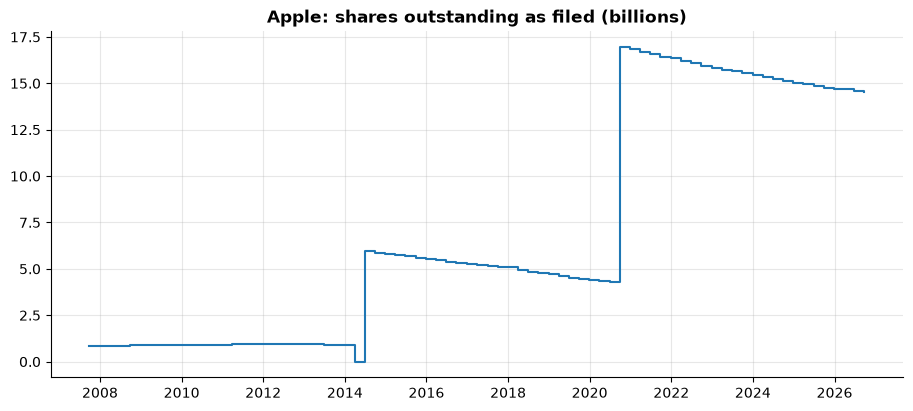

shape: (2, 2)
┌─────────────────────────────────────────────────────┬─────┐
│ tag                                                 ┆ len │
│ ---                                                 ┆ --- │
│ str                                                 ┆ u32 │
╞═════════════════════════════════════════════════════╪═════╡
│ us-gaap:CommonStockSharesOutstanding                ┆ 71  │
│ us-gaap:WeightedAverageNumberOfSharesOutstandingBa… ┆ 1   │
└─────────────────────────────────────────────────────┴─────┘


end,shares,filed,available_from,tag
date,f64,date,date,str
2020-03-28,4.3240e9,2020-05-01,2020-05-02,"""us-gaap:CommonStockSharesOutstanding"""
2020-06-27,4.2839e9,2020-07-31,2020-08-01,"""us-gaap:CommonStockSharesOutstanding"""
2020-09-26,1.6977e10,2020-10-30,2020-10-31,"""us-gaap:CommonStockSharesOutstanding"""
2020-12-26,1.6823e10,2021-01-28,2021-01-29,"""us-gaap:CommonStockSharesOutstanding"""


In [7]:
sh = edgar.shares(AAPL)
fig, ax = plt.subplots()
ax.step(sh["end"], sh["shares"] / 1e9, where="post")
ax.set_title("Apple: shares outstanding as filed (billions)")
plt.show()
print(sh.group_by("tag").len().sort("len", descending=True))
sh.filter(pl.col("end").is_between(date(2020, 3, 1), date(2020, 12, 31))).select("end", "shares", "filed", "available_from", "tag")

## 6 · Per-share items across a split

EPS is kept as filed too. Quarters filed before a split are in old share units and quarters
filed after it in new ones, so a four-quarter sum across the split would mix the two: `ttm` is
left empty for those windows and is the reported annual figure at fiscal year ends. (vinculum
has the security's split history and rebuilds a continuous TTM EPS from these rows.)

In [8]:
eps = edgar.series("eps_diluted", ciks=AAPL).filter(pl.col("end").is_between(date(2019, 12, 1), date(2021, 9, 30)))
eps.sort("end").select("period", "end", "value", "filed", "ttm", "ttm_available_from", "source")

period,end,value,filed,ttm,ttm_available_from,source
str,date,f64,date,f64,date,str
"""quarter""",2019-12-28,4.99,2020-01-29,12.66,2020-01-30,"""reported"""
"""quarter""",2020-03-28,2.55,2020-05-01,12.75,2020-05-02,"""reported"""
"""quarter""",2020-06-27,2.58,2020-07-31,null,null,"""reported"""
"""quarter""",2020-09-26,0.73,2020-10-30,3.28,2020-10-31,"""reported"""
"""annual""",2020-09-26,3.28,2020-10-30,3.28,2020-10-31,"""reported"""
"""quarter""",2020-12-26,1.68,2021-01-28,null,null,"""reported"""
"""quarter""",2021-03-27,1.4,2021-04-29,null,null,"""reported"""
"""quarter""",2021-06-26,1.3,2021-07-28,5.11,2021-07-29,"""reported"""
"""annual""",2021-09-25,5.61,2021-10-29,5.61,2021-10-30,"""reported"""


## 7 · Semi-annual and annual-only filers

Foreign filers report in their own currency and often only twice a year (6-K) or once (20-F).
ASML files in euros: its series has halves (`period="half"`, with `ttm` from two halves) and
reported fiscal years, no quarters.

In [9]:
asml = edgar.series(["revenue", "net_income"], ciks=937966)
print(asml.group_by("item", "period", "unit").len().sort("item", "period"))
asml.filter((pl.col("item") == "revenue") & (pl.col("end") >= date(2023, 1, 1))).sort("end").select(
    "period", "start", "end", "unit", "value", "source", "filed", "ttm")

shape: (2, 4)
┌────────────┬────────┬──────┬─────┐
│ item       ┆ period ┆ unit ┆ len │
│ ---        ┆ ---    ┆ ---  ┆ --- │
│ str        ┆ str    ┆ str  ┆ u32 │
╞════════════╪════════╪══════╪═════╡
│ net_income ┆ annual ┆ EUR  ┆ 19  │
│ revenue    ┆ annual ┆ EUR  ┆ 19  │
└────────────┴────────┴──────┴─────┘


period,start,end,unit,value,source,filed,ttm
str,date,date,str,f64,str,date,f64
"""annual""",2023-01-01,2023-12-31,"""EUR""",2.7558e10,"""reported""",2024-02-14,2.7558e10
"""annual""",2024-01-01,2024-12-31,"""EUR""",2.8263e10,"""reported""",2025-03-05,2.8263e10
"""annual""",2025-01-01,2025-12-31,"""EUR""",3.2667e10,"""reported""",2026-02-25,3.2667e10


## 8 · The materialized tables

Building a series means scanning the facts and deriving periods, about two seconds per item for
10,000 companies. `backfill` and `sync` therefore end by writing every item's series and the share
counts to `series.parquet` and `shares.parquet`, stamped with the version of the facts they came
from; reads use them whenever the versions match and build from the facts otherwise (the same
result). `series_status()` says which path a read takes.

In [10]:
print(edgar.series_status())
ciks = sample["cik"].to_list()
with timed("series of two items for 300 companies, from the materialized table"):
    fast = edgar.series(["revenue", "net_income"], ciks=ciks, materialized=True)
with timed("the same, built from the facts"):
    slow = edgar.series(["revenue", "net_income"], ciks=ciks, materialized=False)
keys = ["item", "cik", "unit", "period", "start", "end"]
print("identical:", fast.sort(keys).equals(slow.sort(keys)), f"({fast.height:,} rows)")

{'built_at': '2026-11-04T20:23:32+00:00', 'facts_version': 1, 'series_facts_version': 1, 'facts_updated_at': '2026-11-04T20:16:41+00:00', 'current': True}
series of two items for 300 companies, from the materialized table: 0.01 s


the same, built from the facts: 0.54 s
identical: True (52,039 rows)


## Takeaways
- The facts table is the source of truth: every filing, every version, with its filing date.
- `series()` derives quarters within one tag, dates derived figures by the later filing, and
  keeps the first-filed value unless asked otherwise.
- `available_from` (filing date + 1) is the only date to use for anything point in time;
  `end` is when the period ended, which is months earlier.
- Shares and per-share items are as filed; splits are visible, and TTM EPS never sums across
  one here.
- Reads come from the materialized tables when they are current (`cortical status` shows it)
  and fall back to the facts when they are not.